# Milestone 2 - Two-model analysis: which model should we improve?

Both models are evaluated on the **same 2,279 validation images**, from the same cached pixels:

| | `scratch` | `q8` |
|---|---|---|
| architecture | 4-level U-Net, 7.76M params | 3-stage U-Net, 1.93M params |
| input | 1 channel, (x/255 - 0.3314)/0.1892 | 3 channels (gray repeated), x/255 |
| training | 15 epochs, flips + brightness/contrast, lr 1e-3 | 5 epochs, no augmentation, lr 3e-4 |
| leaderboard (raw) | 0.49780 (tau 0.8) | 0.45898 (tau 0.5) |

## Setup

In [2]:
import os, glob, time, json, itertools
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

IMG_H, IMG_W = 128, 800
DEFECTS = ["defect_a", "defect_b", "defect_c", "defect_d"]
RUN_TTA = True          # set False to skip the flip-TTA candidates (saves a few minutes)
BS = 16

def find_file(name, known=None):
    if known and os.path.exists(known):
        return known
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    if not hits:
        raise FileNotFoundError(f"{name} not found - attach the right input to this notebook")
    return hits[0]

def find_image_dir(sample_id):
    hits = glob.glob(f"/kaggle/input/**/{sample_id}.*", recursive=True)
    if not hits:
        raise FileNotFoundError(f"image {sample_id} not found - attach the competition data")
    return os.path.dirname(hits[0])

TRAIN_CSV = find_file("train.csv", "/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv")
HOLDOUT_CSV = find_file("holdout.csv", "/kaggle/input/notebooks/mruniksurya/milestone-1/holdout.csv")
CKPT_SCRATCH = find_file("best_unet_scratch.pt", "/kaggle/input/notebooks/mruniksurya/milestone-2/best_unet_scratch.pt")
CKPT_Q8 = find_file("best_unet_q8.pt", "/kaggle/input/notebooks/mruniksurya/milestone-2-q8/best_unet_q8.pt")
print(CKPT_SCRATCH); print(CKPT_Q8)

/kaggle/input/notebooks/mruniksurya/milestone-2/best_unet_scratch.pt
/kaggle/input/notebooks/mruniksurya/milestone-2-q8/best_unet_q8.pt


## Code blocks (RLE, models, preprocessing, metric, tuning)
The model classes are copied unchanged from the training notebooks so that the saved weights load. `to_input` builds each model's own input from the same grayscale pixels. `tune` and `apply_params` implement the post-processing search described in section 6.

In [3]:
def rle_decode(rle, shape=(IMG_H, IMG_W)):
    """1-based, column-major RLE string -> binary (H, W) mask. NaN / blank -> all zeros."""
    flat = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    if isinstance(rle, str) and rle.strip():
        tok = np.array(rle.split(), dtype=np.int64)
        starts = tok[0::2] - 1
        ends = starts + tok[1::2]
        for s, e in zip(starts, ends):
            flat[max(s, 0):min(e, flat.size)] = 1
    return flat.reshape(shape, order="F")

def rle_encode(mask):
    """Binary (H, W) mask -> RLE string (1-based, column-major). Empty mask -> empty string."""
    flat = np.asarray(mask).flatten(order="F")
    padded = np.concatenate([[0], flat, [0]])
    k = np.where(padded[1:] != padded[:-1])[0] + 1
    return " ".join(f"{s} {e - s}" for s, e in zip(k[0::2], k[1::2]))

In [4]:
import torch
import torch.nn as nn

class DoubleConv(nn.Module):
    """(Conv3x3 -> BatchNorm -> ReLU) x 2 : the basic U-Net building block."""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
    def forward(self, x):
        return self.block(x)

class UNetScratch(nn.Module):
    """Milestone-2 main model: 4 encoder levels, 1 input channel, 4 logits. 7,762,564 parameters."""
    def __init__(self, in_ch=1, n_classes=4, base=32):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]
        self.enc1, self.enc2 = DoubleConv(in_ch, c[0]), DoubleConv(c[0], c[1])
        self.enc3, self.enc4 = DoubleConv(c[1], c[2]), DoubleConv(c[2], c[3])
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(c[3], c[4])
        self.up4, self.dec4 = nn.ConvTranspose2d(c[4], c[3], 2, stride=2), DoubleConv(c[3] * 2, c[3])
        self.up3, self.dec3 = nn.ConvTranspose2d(c[3], c[2], 2, stride=2), DoubleConv(c[2] * 2, c[2])
        self.up2, self.dec2 = nn.ConvTranspose2d(c[2], c[1], 2, stride=2), DoubleConv(c[1] * 2, c[1])
        self.up1, self.dec1 = nn.ConvTranspose2d(c[1], c[0], 2, stride=2), DoubleConv(c[0] * 2, c[0])
        self.head = nn.Conv2d(c[0], n_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.head(d1)

class UNet3Stage(nn.Module):
    """Q8 model: 3 down stages, 3 input channels (gray replicated), 4 logits. 1,927,108 parameters."""
    def __init__(self, in_ch=3, out_ch=4, base=32):
        super().__init__()
        self.enc1 = DoubleConv(in_ch, base)
        self.enc2 = DoubleConv(base, base * 2)
        self.enc3 = DoubleConv(base * 2, base * 4)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(base * 4, base * 8)
        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, 2, stride=2)
        self.dec3 = DoubleConv(base * 8, base * 4)
        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.dec2 = DoubleConv(base * 4, base * 2)
        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.dec1 = DoubleConv(base * 2, base)
        self.head = nn.Conv2d(base, out_ch, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        b = self.bottleneck(self.pool(e3))
        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.head(d1)

def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

In [5]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', DEVICE)

IMG_MEAN, IMG_STD = 0.3314, 0.1892      # training-set statistics used by the scratch model (milestone-2 notebook)

def to_input(u8, kind):
    """u8: (B,H,W) uint8 grayscale -> model input tensor.
    scratch: (pixel/255 - mean)/std, 1 channel.   q8: pixel/255 only, gray replicated to 3 channels (what cv2 BGR->RGB gave)."""
    x = torch.from_numpy(np.ascontiguousarray(u8)).float().div_(255.0)
    if kind == "scratch":
        return ((x - IMG_MEAN) / IMG_STD).unsqueeze(1)
    return x.unsqueeze(1).repeat(1, 3, 1, 1)

@torch.no_grad()
def predict_probs(model, kind, u8, tta=False):
    """Sigmoid probabilities (B,4,H,W) on the GPU. tta=True averages the plain image with its horizontal and vertical flip."""
    x = to_input(u8, kind).to(DEVICE)
    p = torch.sigmoid(model(x))
    if tta:
        p = p + torch.sigmoid(model(x.flip(-1))).flip(-1)      # horizontal flip, un-flip the output
        p = p + torch.sigmoid(model(x.flip(-2))).flip(-2)      # vertical flip, un-flip the output
        p = p / 3.0
    return p

def load_model(kind, ckpt):
    m = UNetScratch(in_ch=1, n_classes=4, base=32) if kind == "scratch" else UNet3Stage(in_ch=3, out_ch=4, base=32)
    m.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    return m.to(DEVICE).eval()

device: cuda


In [6]:
CANVAS_PIXELS = IMG_H * IMG_W

def dice_empty_aware(inter, pred_area, gt_area):
    inter, pred_area, gt_area = (np.asarray(a, dtype=np.float64) for a in (inter, pred_area, gt_area))
    denom = pred_area + gt_area
    dice = np.where(denom > 0, 2 * inter / np.maximum(denom, 1), 0.0)
    return np.where((pred_area == 0) & (gt_area == 0), 1.0, dice)

def competition_score(inter, pred_area, gt_area, canvas=CANVAS_PIXELS, weights=(0.70, 0.20, 0.10)):
    inter, pred_area, gt_area = (np.asarray(a, dtype=np.float64) for a in (inter, pred_area, gt_area))
    positive = gt_area > 0
    empty = ~positive
    dice = dice_empty_aware(inter, pred_area, gt_area)
    fg = dice[positive].mean()
    fp = 1 - (pred_area[empty] / canvas).mean()
    ea = (pred_area[empty] == 0).mean()
    return {"foreground_dice": fg, "false_positive_score": fp, "empty_accuracy": ea,
            "score": weights[0] * fg + weights[1] * fp + weights[2] * ea}

In [7]:
import cv2

def postprocess(prob, tau, min_area, gate):
    """prob (H,W) of ONE (image, class) pair -> binary uint8 mask.
    gate: if the most confident pixel is below it, the whole mask is emptied.
    min_area: connected regions (8-connectivity) smaller than this many pixels are removed."""
    if prob.max() < gate:
        return np.zeros(prob.shape, dtype=np.uint8)
    mask = (prob > tau).astype(np.uint8)
    if min_area > 0 and mask.any():
        n, lab, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
        keep = np.zeros(n, dtype=bool)
        keep[1:] = stats[1:, cv2.CC_STAT_AREA] >= min_area
        mask = keep[lab].astype(np.uint8)
    return mask

In [8]:
def both_scores(inter, pred_area, gt_area, rows=None):
    """Reading A = helper formula (FP score = 1 - mean predicted fraction on empty pairs).
    Reading B = per-pair reading: 0.7 * foreground Dice + 0.3 * empty accuracy (any pixel on an empty pair is a failure).
    rows: optional boolean mask over images to score only a subset."""
    inter, pred_area, gt_area = (np.asarray(a, dtype=np.float64) for a in (inter, pred_area, gt_area))
    if rows is not None:
        inter, pred_area, gt_area = inter[rows], pred_area[rows], gt_area[rows]
    m = competition_score(inter.ravel(), pred_area.ravel(), gt_area.ravel())
    return dict(A=m["score"], B=0.7 * m["foreground_dice"] + 0.3 * m["empty_accuracy"],
                fg=m["foreground_dice"], fp=m["false_positive_score"], ea=m["empty_accuracy"])

def auc_score(score, label):
    """P(random positive pair scores higher than random empty pair); ties count half (Mann-Whitney)."""
    score, label = np.asarray(score, dtype=np.float64), np.asarray(label, dtype=bool)
    order = np.argsort(score, kind="mergesort")
    s = score[order]
    _, inv, counts = np.unique(s, return_inverse=True, return_counts=True)
    avg_rank = np.cumsum(counts) - (counts - 1) / 2.0
    ranks = np.empty(len(score)); ranks[order] = avg_rank[inv]
    n1, n0 = label.sum(), (~label).sum()
    return float((ranks[label].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))

def build_tables(P, GT, tau):
    """Measure every predicted connected region once: pair id (= image*4 + class), area, pixels that are truly defect."""
    pair, area, inter = [], [], []
    for i in range(P.shape[0]):
        for k in range(4):
            pred = (P[i, k].astype(np.float32) > tau).astype(np.uint8)
            if pred.any():
                num, lab, stats, _ = cv2.connectedComponentsWithStats(pred, connectivity=8)
                a = stats[1:, cv2.CC_STAT_AREA].astype(np.int64)
                c = np.bincount(lab[GT[i, k]], minlength=num)[1:].astype(np.int64)
                pair.append(np.full(a.size, i * 4 + k)); area.append(a); inter.append(c)
    if not pair:
        z = np.zeros(0, dtype=np.int64)
        return dict(pair=z, area=z, inter=z)
    return dict(pair=np.concatenate(pair), area=np.concatenate(area), inter=np.concatenate(inter))

def apply_params(T, maxp, N, G):
    """Apply min-area N[k] and gate G[k] per class using the tables -> (inter, pred_area), each (n,4). No images needed."""
    cls = T["pair"] % 4
    keep = (T["area"] >= np.asarray(N)[cls]) & (maxp.ravel()[T["pair"]] >= np.asarray(G)[cls])
    size = maxp.size
    pa = np.bincount(T["pair"][keep], weights=T["area"][keep], minlength=size)
    it = np.bincount(T["pair"][keep], weights=T["inter"][keep], minlength=size)
    return it.reshape(-1, 4), pa.reshape(-1, 4)

N_GRID = [0, 25, 50, 100, 200, 300, 500, 800, 1200, 2000]
G_GRID = [0.0, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.98]

def objective(s, mode):
    return s["B"] if mode == "B" else (s["A"] if mode == "A" else 0.5 * (s["A"] + s["B"]))

def tune(T, maxp, gt_area, rows, mode, passes=2):
    """Coordinate search: for each class in turn try every (min_area, gate) pair, others fixed; repeat."""
    N, G = [0] * 4, [0.0] * 4
    def score(N_, G_):
        it, pa = apply_params(T, maxp, N_, G_)
        return objective(both_scores(it, pa, gt_area, rows), mode)
    best = score(N, G)
    for _ in range(passes):
        improved = False
        for k in range(4):
            for n_ in N_GRID:
                for g_ in G_GRID:
                    N2, G2 = list(N), list(G); N2[k], G2[k] = n_, g_
                    o = score(N2, G2)
                    if o > best + 1e-9:
                        best, N, G, improved = o, N2, G2, True
        if not improved:
            break
    return N, G, best

In [9]:
TAUS_SEARCH = [0.5, 0.7, 0.85]

def analyse(name, P, config):
    """Full evaluation of one candidate (a probability array (n,4,H,W)): raw score, tuned score, held-out tuned score, headroom."""
    n = P.shape[0]
    pos = GT_AREA > 0
    maxp = P.max(axis=(2, 3)).astype(np.float32)

    pred = P > 0.5
    raw = both_scores((pred & GT).sum(axis=(2, 3)), pred.sum(axis=(2, 3)), GT_AREA)
    del pred

    best = None
    for tau in TAUS_SEARCH:
        T = build_tables(P, GT, tau)
        N, G, o = tune(T, maxp, GT_AREA, None, OBJ_MODE)
        if best is None or o > best["obj"]:
            best = dict(tau=tau, N=N, G=G, obj=o, T=T)
    T, tau, N, G = best["T"], best["tau"], best["N"], best["G"]
    it, pa = apply_params(T, maxp, N, G)
    tuned = both_scores(it, pa, GT_AREA)

    # honest check of the tuning: tune on one random half of the images, score on the other half (both ways)
    rng = np.random.default_rng(0)
    half = np.zeros(n, dtype=bool); half[rng.permutation(n)[: n // 2]] = True
    held, held_raw = [], []
    it0, pa0 = apply_params(T, maxp, [0] * 4, [0.0] * 4)
    for train_rows in (half, ~half):
        N2, G2, _ = tune(T, maxp, GT_AREA, train_rows, OBJ_MODE)
        it2, pa2 = apply_params(T, maxp, N2, G2)
        held.append(both_scores(it2, pa2, GT_AREA, ~train_rows))
        held_raw.append(both_scores(it0, pa0, GT_AREA, ~train_rows))
    avg = lambda L, key: float(np.mean([d[key] for d in L]))

    # headroom: what if every empty pair were predicted perfectly empty (oracle gate)?
    oracle = both_scores(it, np.where(pos, pa, 0), GT_AREA)
    detected = pos & (it > 0)
    dice_det = dice_empty_aware(it[detected], pa[detected], GT_AREA[detected]).mean() if detected.any() else 0.0

    return dict(name=name, raw_A=raw["A"], raw_B=raw["B"], tau=tau, N=N, G=G,
                tuned_A=tuned["A"], tuned_B=tuned["B"], tuned_fg=tuned["fg"], tuned_ea=tuned["ea"],
                held_A=avg(held, "A"), held_B=avg(held, "B"), heldraw_A=avg(held_raw, "A"), heldraw_B=avg(held_raw, "B"),
                oracle_gate_A=oracle["A"], oracle_gate_B=oracle["B"],
                recall_pairs=float(detected.sum() / pos.sum()), dice_when_detected=float(dice_det),
                auc=[auc_score(maxp[:, k], pos[:, k]) for k in range(4)],
                pred_pos_rate=[float((pa[:, k] > 0).mean()) for k in range(4)],
                config=dict(config, tau=float(tau), min_area=[int(v) for v in N], gate=[float(v) for v in G]))

## Validation images and ground truth (loaded once)

In [10]:
hold = pd.read_csv(HOLDOUT_CSV)
val_ids = sorted(set(hold.loc[hold["split"].astype(str).str.lower().isin({"val", "valid", "validation", "holdout"}), "image_id"]))
assert len(val_ids) == 2279, len(val_ids)
long = pd.read_csv(TRAIN_CSV)
rle_table = long.pivot(index="image_id", columns="defect_type", values="mask_rle")[DEFECTS]

IMG_DIR = find_image_dir(val_ids[0])
files = {os.path.splitext(f)[0]: f for f in os.listdir(IMG_DIR)}
n = len(val_ids)
IMGS = np.zeros((n, IMG_H, IMG_W), dtype=np.uint8)
GT = np.zeros((n, 4, IMG_H, IMG_W), dtype=bool)
for i, iid in enumerate(val_ids):
    g = cv2.imread(os.path.join(IMG_DIR, files[iid]), cv2.IMREAD_GRAYSCALE)
    assert g is not None and g.shape == (IMG_H, IMG_W), (iid, None if g is None else g.shape)
    IMGS[i] = g
    for k, d in enumerate(DEFECTS):
        GT[i, k] = rle_decode(rle_table.at[iid, d])
GT_AREA = GT.sum(axis=(2, 3))
print("images:", IMGS.shape, "| pairs:", GT_AREA.size, "| true empty rate:", round(float((GT_AREA == 0).mean()), 4))

# the Q8 pipeline read images with cv2 in colour (BGR->RGB). Check that this equals the gray image repeated 3 times.
bad = 0
for iid in val_ids[:30]:
    c = cv2.cvtColor(cv2.imread(os.path.join(IMG_DIR, files[iid]), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    g = cv2.imread(os.path.join(IMG_DIR, files[iid]), cv2.IMREAD_GRAYSCALE)
    bad += int(not (np.array_equal(c[..., 0], g) and np.array_equal(c[..., 1], g) and np.array_equal(c[..., 2], g)))
print("images where colour channels differ from the gray image (should be 0):", bad)

images: (2279, 128, 800) | pairs: 9116 | true empty rate: 0.8419
images where colour channels differ from the gray image (should be 0): 0


## Predictions of both models

In [11]:
def predict_all(kind, ckpt, tta):
    model = load_model(kind, ckpt)
    P = np.empty((n, 4, IMG_H, IMG_W), dtype=np.float16)
    for s in range(0, n, BS):
        P[s:s + BS] = predict_probs(model, kind, IMGS[s:s + BS], tta).half().cpu().numpy()
    del model; torch.cuda.empty_cache()
    return P

BASE = {}
for key, kind, ckpt, tta in [("S", "scratch", CKPT_SCRATCH, False), ("Q", "q8", CKPT_Q8, False),
                             ("S_tta", "scratch", CKPT_SCRATCH, True), ("Q_tta", "q8", CKPT_Q8, True)]:
    if tta and not RUN_TTA:
        continue
    t0 = time.time()
    BASE[key] = predict_all(kind, ckpt, tta)
    print(f"{key}: done in {time.time() - t0:.0f}s")

S: done in 23s
Q: done in 19s
S_tta: done in 67s
Q_tta: done in 65s


## Does the pipeline reproduce the training-time validation scores?

In [12]:
expected = {"S": 0.6020, "Q": 0.5853}
for key in ["S", "Q"]:
    pred = BASE[key] > 0.5
    s = both_scores((pred & GT).sum(axis=(2, 3)), pred.sum(axis=(2, 3)), GT_AREA)
    ok = abs(s["A"] - expected[key]) < 0.01
    print(f"{key}: score A {s['A']:.4f} (training log {expected[key]:.4f}) -> {'OK' if ok else 'CHECK PREPROCESSING'}")
    del pred

S: score A 0.6020 (training log 0.6020) -> OK
Q: score A 0.5853 (training log 0.5853) -> OK


In [13]:
refs = [("scratch, raw tau 0.8", "S", 0.8, 0.49780), ("q8, raw tau 0.5", "Q", 0.5, 0.45898)]
rows = []
for label, key, tau, lb in refs:
    pred = BASE[key] > tau
    s = both_scores((pred & GT).sum(axis=(2, 3)), pred.sum(axis=(2, 3)), GT_AREA)
    rows.append(dict(submission=label, val_A=s["A"], val_B=s["B"], leaderboard=lb, A_minus_LB=s["A"] - lb, B_minus_LB=s["B"] - lb))
    del pred
chk = pd.DataFrame(rows).set_index("submission").round(4)
print(chk.to_string())

if (chk["B_minus_LB"].abs() < 0.015).all():
    OBJ_MODE = "B"
elif (chk["A_minus_LB"].abs() < 0.015).all():
    OBJ_MODE = "A"
else:
    OBJ_MODE = "mix"
print("\nobjective used for tuning:", OBJ_MODE, "(B = per-pair reading, A = area reading, mix = average of both)")

                       val_A   val_B  leaderboard  A_minus_LB  B_minus_LB
submission                                                               
scratch, raw tau 0.8  0.6028  0.4930       0.4978      0.1050     -0.0048
q8, raw tau 0.5       0.5853  0.4985       0.4590      0.1263      0.0395

objective used for tuning: mix (B = per-pair reading, A = area reading, mix = average of both)


## Per-class diagnosis at tau 0.5

In [14]:
def diag(P, tau=0.5):
    pred = P > tau
    pa, it = pred.sum(axis=(2, 3)), (pred & GT).sum(axis=(2, 3))
    maxp = P.max(axis=(2, 3)).astype(np.float32)
    rows = []
    for k, d in enumerate(DEFECTS):
        pos = GT_AREA[:, k] > 0
        rows.append(dict(cls=d, true_pos_rate=pos.mean(), pred_pos_rate=(pa[:, k] > 0).mean(),
                         recall_pairs=(it[pos, k] > 0).mean(),
                         fg_dice=dice_empty_aware(it[pos, k], pa[pos, k], GT_AREA[pos, k]).mean(),
                         empty_acc=(pa[~pos, k] == 0).mean(), auc_maxp=auc_score(maxp[:, k], pos)))
    return pd.DataFrame(rows).set_index("cls").round(3)

for key in ["S", "Q"]:
    print(f"--- {key} ({'scratch' if key == 'S' else 'q8'}) at tau 0.5"); print(diag(BASE[key]).to_string()); print()

--- S (scratch) at tau 0.5
          true_pos_rate  pred_pos_rate  recall_pairs  fg_dice  empty_acc  auc_maxp
cls                                                                               
defect_a          0.095          0.625         0.676    0.340      0.397     0.711
defect_b          0.028          0.600         0.667    0.336      0.407     0.721
defect_c          0.360          0.762         0.896    0.549      0.341     0.831
defect_d          0.150          0.694         0.965    0.613      0.357     0.901

--- Q (q8) at tau 0.5
          true_pos_rate  pred_pos_rate  recall_pairs  fg_dice  empty_acc  auc_maxp
cls                                                                               
defect_a          0.095          0.604         0.597    0.267      0.415     0.687
defect_b          0.028          0.000         0.000    0.000      1.000     0.470
defect_c          0.360          0.882         0.922    0.519      0.173     0.812
defect_d          0.150          0.57

## Post-processing search for six candidates

In [15]:
def cand_probs(keys):
    if len(keys) == 1:
        return BASE[keys[0]]
    acc = BASE[keys[0]].astype(np.float32)
    for k in keys[1:]:
        acc += BASE[k].astype(np.float32)
    return (acc / len(keys)).astype(np.float16)

CANDS = [
    ("scratch",               ["S"],          dict(models=["scratch"],       tta={"scratch": False})),
    ("scratch + flip-TTA",    ["S_tta"],      dict(models=["scratch"],       tta={"scratch": True})),
    ("q8",                    ["Q"],          dict(models=["q8"],            tta={"q8": False})),
    ("q8 + flip-TTA",         ["Q_tta"],      dict(models=["q8"],            tta={"q8": True})),
    ("ensemble",              ["S", "Q"],     dict(models=["scratch", "q8"], tta={"scratch": False, "q8": False})),
    ("ensemble (scratch TTA)", ["S_tta", "Q"], dict(models=["scratch", "q8"], tta={"scratch": True, "q8": False})),
]
CANDS = [c for c in CANDS if all(k in BASE for k in c[1])]

results = []
for name, keys, cfg in CANDS:
    t0 = time.time()
    r = analyse(name, cand_probs(keys), cfg)
    r["keys"] = keys
    results.append(r)
    print(f"{name:24s} raw {r['raw_A']:.4f}/{r['raw_B']:.4f} -> tuned {r['tuned_A']:.4f}/{r['tuned_B']:.4f} | held-out {r['held_A']:.4f}/{r['held_B']:.4f} | tau {r['tau']} | {time.time() - t0:.0f}s")

scratch                  raw 0.6020/0.4800 -> tuned 0.6220/0.5732 | held-out 0.6197/0.5712 | tau 0.5 | 44s
scratch + flip-TTA       raw 0.6119/0.4993 -> tuned 0.6263/0.5860 | held-out 0.6255/0.5836 | tau 0.5 | 41s
q8                       raw 0.5853/0.4985 -> tuned 0.5928/0.5543 | held-out 0.5905/0.5520 | tau 0.5 | 32s
q8 + flip-TTA            raw 0.5861/0.5044 -> tuned 0.5918/0.5498 | held-out 0.5922/0.5477 | tau 0.5 | 30s
ensemble                 raw 0.6036/0.5095 -> tuned 0.6210/0.5808 | held-out 0.6178/0.5794 | tau 0.5 | 43s
ensemble (scratch TTA)   raw 0.6087/0.5178 -> tuned 0.6238/0.5846 | held-out 0.6220/0.5831 | tau 0.5 | 42s


## Summary table and chart

                candidate   raw_A   raw_B  held_A  held_B  tuned_fg  tuned_empty_acc  auc_mean  tau  objective_held  est_LB_B  gap_to_0.65
0      scratch + flip-TTA  0.6119  0.4993  0.6255  0.5836    0.4978           0.7918    0.7984  0.5          0.6046    0.5836       0.0664
1  ensemble (scratch TTA)  0.6087  0.5178  0.6220  0.5831    0.4930           0.7983    0.7821  0.5          0.6025    0.5831       0.0669
2                ensemble  0.6036  0.5095  0.6178  0.5794    0.4894           0.7940    0.7751  0.5          0.5986    0.5794       0.0706
3                 scratch  0.6020  0.4800  0.6197  0.5712    0.4983           0.7480    0.7910  0.5          0.5955    0.5712       0.0788
4                      q8  0.5853  0.4985  0.5905  0.5520    0.4492           0.7995    0.7156  0.5          0.5712    0.5520       0.0980
5           q8 + flip-TTA  0.5861  0.5044  0.5922  0.5477    0.4502           0.7821    0.7114  0.5          0.5700    0.5477       0.1023


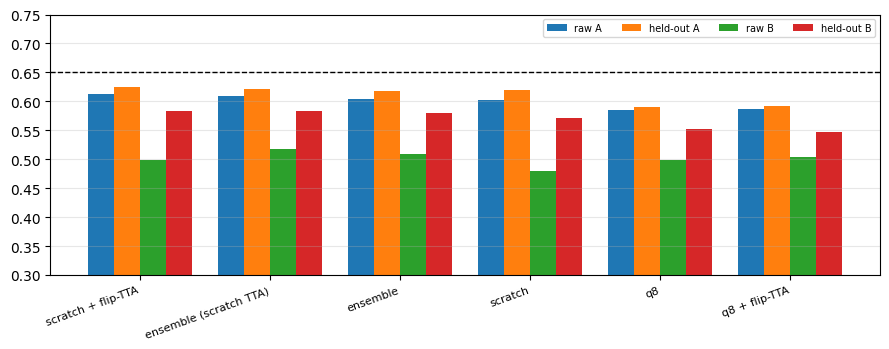


best candidate: scratch + flip-TTA
CONFIG to paste into the inference notebook:
{"models": ["scratch"], "tta": {"scratch": true}, "tau": 0.5, "min_area": [0, 500, 200, 300], "gate": [0.98, 0.98, 0.9, 0.98]}


In [16]:
S_ = pd.DataFrame([dict(candidate=r["name"], raw_A=r["raw_A"], raw_B=r["raw_B"], held_A=r["held_A"], held_B=r["held_B"],
                        tuned_fg=r["tuned_fg"], tuned_empty_acc=r["tuned_ea"], auc_mean=np.mean(r["auc"]), tau=r["tau"]) for r in results])
S_["objective_held"] = [objective(dict(A=a, B=b), OBJ_MODE) for a, b in zip(S_["held_A"], S_["held_B"])]
S_["est_LB_B"] = S_["held_B"]
S_["gap_to_0.65"] = 0.65 - S_["est_LB_B"]
S_ = S_.sort_values("objective_held", ascending=False).reset_index(drop=True)
print(S_.round(4).to_string())
S_.round(5).to_csv("/kaggle/working/analysis_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(S_)); w = 0.2
for j, (col, lab) in enumerate([("raw_A", "raw A"), ("held_A", "held-out A"), ("raw_B", "raw B"), ("held_B", "held-out B")]):
    ax.bar(x + (j - 1.5) * w, S_[col], w, label=lab)
ax.set_xticks(x); ax.set_xticklabels(S_["candidate"], rotation=20, ha="right", fontsize=8)
ax.axhline(0.65, color="k", ls="--", lw=1); ax.set_ylim(0.3, 0.75); ax.legend(fontsize=7, ncol=4); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.savefig("/kaggle/working/analysis_candidates.png", dpi=130); plt.show()

by_name = {r["name"]: r for r in results}
configs = {r["name"]: r["config"] for r in results}
json.dump(configs, open("/kaggle/working/post_configs.json", "w"), indent=1)
best_name = S_.loc[0, "candidate"]
print("\nbest candidate:", best_name)
print("CONFIG to paste into the inference notebook:"); print(json.dumps(configs[best_name]))

In [17]:
H = pd.DataFrame([dict(candidate=r["name"], tuned_A=r["tuned_A"], tuned_B=r["tuned_B"], oracle_gate_A=r["oracle_gate_A"], oracle_gate_B=r["oracle_gate_B"],
                       recall_pairs=r["recall_pairs"], dice_when_detected=r["dice_when_detected"],
                       auc_a=r["auc"][0], auc_b=r["auc"][1], auc_c=r["auc"][2], auc_d=r["auc"][3]) for r in results]).set_index("candidate")
print(H.round(3).to_string())
print()
for r in results:
    print(f"{r['name']:24s} tau {r['tau']} | min_area {r['N']} | gate {[round(g, 2) for g in r['G']]} | predicted positive rate per class {[round(v, 3) for v in r['pred_pos_rate']]}")
print("true positive rate per class:", [round(float((GT_AREA[:, k] > 0).mean()), 3) for k in range(4)])

                        tuned_A  tuned_B  oracle_gate_A  oracle_gate_B  recall_pairs  dice_when_detected  auc_a  auc_b  auc_c  auc_d
candidate                                                                                                                           
scratch                   0.622    0.573          0.649          0.649         0.786               0.634  0.711  0.721  0.831  0.901
scratch + flip-TTA        0.626    0.586          0.648          0.648         0.770               0.646  0.718  0.732  0.836  0.908
q8                        0.593    0.554          0.614          0.614         0.752               0.598  0.687  0.470  0.812  0.893
q8 + flip-TTA             0.592    0.550          0.615          0.615         0.750               0.600  0.664  0.476  0.808  0.898
ensemble                  0.621    0.581          0.643          0.643         0.774               0.632  0.719  0.635  0.839  0.909
ensemble (scratch TTA)    0.624    0.585          0.645          0.64

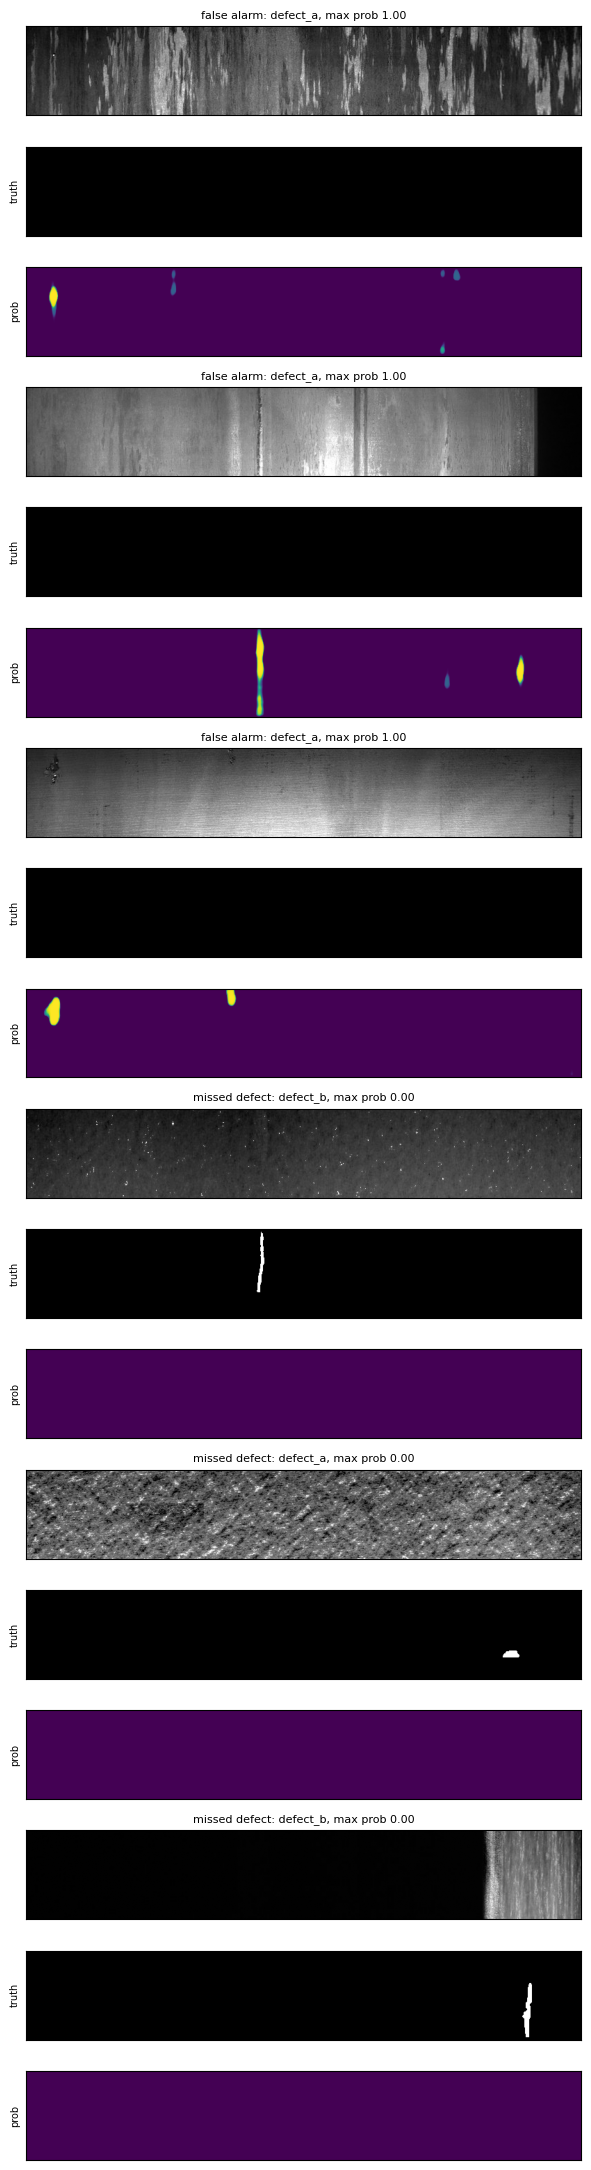

In [18]:
P_best = cand_probs(by_name[best_name]["keys"])
maxp = P_best.max(axis=(2, 3)).astype(np.float32)
pos = GT_AREA > 0
fp_idx = np.argwhere(~pos)[np.argsort(-maxp[~pos])[:3]]
miss_idx = np.argwhere(pos)[np.argsort(maxp[pos])[:3]]
cases = [("false alarm", i, k) for i, k in fp_idx] + [("missed defect", i, k) for i, k in miss_idx]

fig, axes = plt.subplots(len(cases) * 3, 1, figsize=(12, 2.0 * len(cases) * 3 * 0.55 + 2))
for c, (kind_, i, k) in enumerate(cases):
    a0, a1, a2 = axes[3 * c], axes[3 * c + 1], axes[3 * c + 2]
    a0.imshow(IMGS[i], cmap="gray"); a0.set_title(f"{kind_}: {DEFECTS[k]}, max prob {maxp[i, k]:.2f}", fontsize=8)
    a1.imshow(GT[i, k], cmap="gray", vmin=0, vmax=1); a1.set_ylabel("truth", fontsize=7)
    a2.imshow(P_best[i, k].astype(np.float32), cmap="viridis", vmin=0, vmax=1); a2.set_ylabel("prob", fontsize=7)
    for a in (a0, a1, a2): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig("/kaggle/working/analysis_cases.png", dpi=110); plt.show()